# Import Libraries and Set Visualization Theme

In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
sns.set_theme(style="whitegrid", context="notebook")

print("Libraries imported successfully!")

Libraries imported successfully!


# Load your SQL results

In [4]:
db_path = Path(
    r"C:\Users\bhumi\Downloads\Mint Technologies\Retail_Sales_Cleaning\analysis.db"
)

conn = sqlite3.connect(db_path)

In [5]:
query1 = """
SELECT
    product_name,
    ROUND(SUM(sales), 2) AS total_sales
FROM sales
GROUP BY product_name
ORDER BY total_sales DESC
LIMIT 10;
"""

result1 = pd.read_sql(query1, conn)
display(result1)

,product_name,total_sales
0,Canon imageCLASS 2200 Advanced Copier,61599.82
1,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.38
2,Cisco TelePresence System EX90 Videoconferenci...,22638.48
3,HON 5400 Series Task Chairs for Big and Tall,21870.58
4,GBC DocuBind TL300 Electric Binding System,19823.48
5,GBC Ibimaster 500 Manual ProClick Binding System,19024.50
6,Hewlett Packard LaserJet 3310 Copier,18839.69
7,HP Designjet T520 Inkjet Large Format Printer ...,18374.90
8,GBC DocuBind P400 Electric Binding System,17965.07
9,High Speed Automatic Electric Letter Opener,17030.31


In [6]:
query2 = """
SELECT
    strftime('%Y-%m', order_date) AS sales_month,
    ROUND(SUM(sales), 2) AS total_sales
FROM sales
WHERE order_date IS NOT NULL
GROUP BY strftime('%Y-%m', order_date)
ORDER BY sales_month;
"""

result2 = pd.read_sql(query2, conn)
display(result2)

,sales_month,total_sales
0,2015-01,14205.71
1,2015-02,4519.89
2,2015-03,55205.80
3,2015-04,27906.85
4,2015-05,23644.30
5,2015-06,34322.94
6,2015-07,33781.54
7,2015-08,27117.54
8,2015-09,81623.53
9,2015-10,31453.39


In [7]:
query3 = """
SELECT
    region,
    ROUND(SUM(sales), 2) AS total_sales
FROM sales
GROUP BY region
ORDER BY total_sales DESC;
"""

result3 = pd.read_sql(query3, conn)
display(result3)

,region,total_sales
0,West,710219.68
1,East,669518.73
2,Central,492646.91
3,South,389151.46


In [8]:
query4 = """
SELECT
    segment,
    ROUND(AVG(order_value), 2) AS average_order_value
FROM (
    SELECT
        order_id,
        segment,
        SUM(sales) AS order_value
    FROM sales
    GROUP BY order_id, segment
)
GROUP BY segment
ORDER BY average_order_value DESC;
"""

result4 = pd.read_sql(query4, conn)
display(result4)

,segment,average_order_value
0,Home Office,475.37
1,Corporate,461.77
2,Consumer,452.53


In [9]:
query5 = """
SELECT
    category,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(AVG(sales), 2) AS average_sales
FROM sales
GROUP BY category
ORDER BY total_sales DESC;
"""

result5 = pd.read_sql(query5, conn)
display(result5)

,category,total_sales,average_sales
0,Technology,827455.87,456.40
1,Furniture,728658.58,350.65
2,Office Supplies,705422.33,119.38


In [10]:
print("All five SQL results loaded successfully!")

All five SQL results loaded successfully!


# Visualization 1: Top 10 Products by Sales

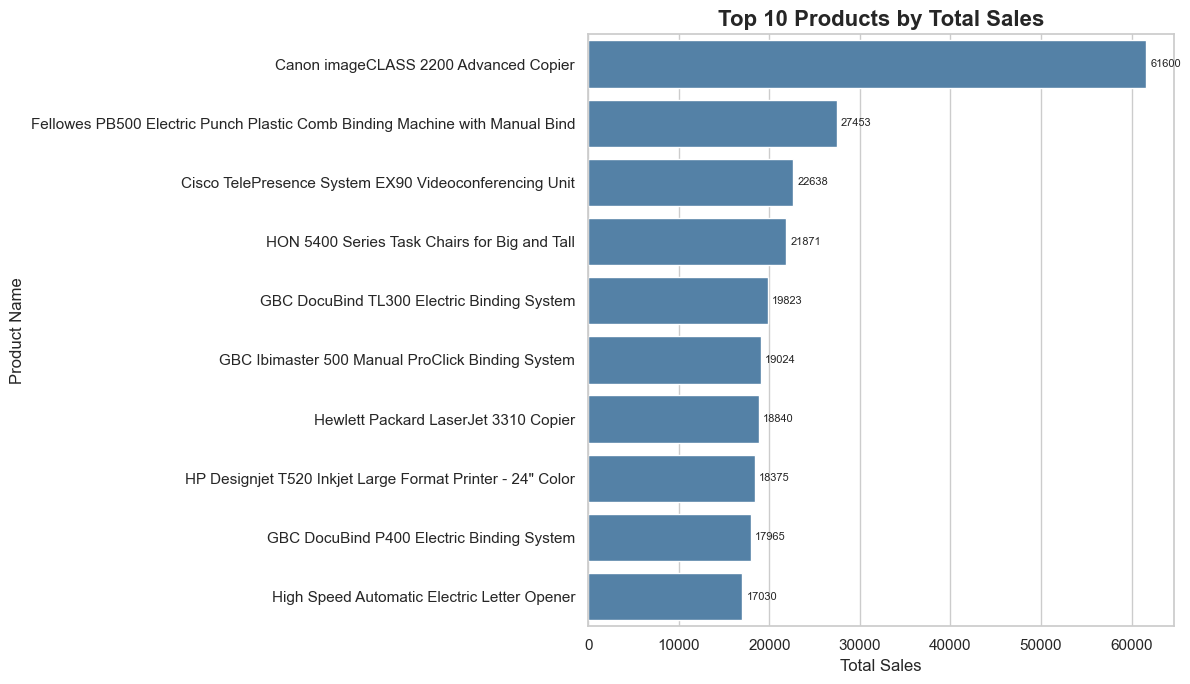

In [11]:
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=result1,
    x="total_sales",
    y="product_name",
    color="steelblue"
)

ax.set_title("Top 10 Products by Total Sales", fontsize=16, weight="bold")
ax.set_xlabel("Total Sales")
ax.set_ylabel("Product Name")
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3, fontsize=8)

plt.tight_layout()
plt.show()

# Business takeaway :
This chart identifies the products contributing the most to total sales. The highest-selling products may be prioritized for inventory planning and promotional campaigns.

# Visualization 2: Monthly Sales Trend

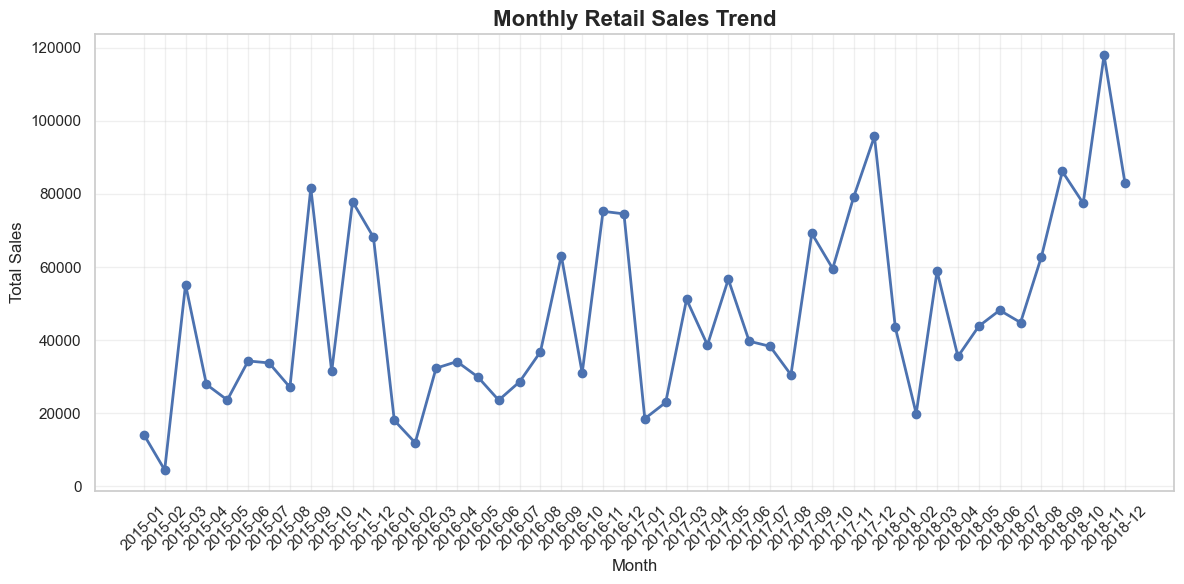

In [12]:
plt.figure(figsize=(12, 6))

plt.plot(
    result2["sales_month"],
    result2["total_sales"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Retail Sales Trend", fontsize=16, weight="bold")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Business takeaway:
Monthly sales patterns help identify periods of higher and lower demand. These trends can guide future sales planning and inventory preparation.

# Visualization 3: Sales by Region

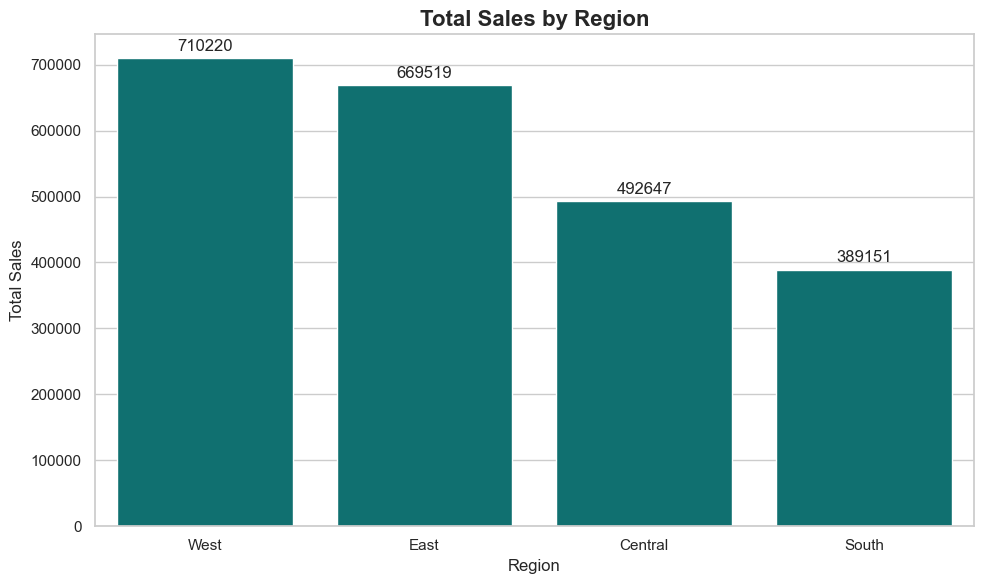

In [13]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=result3,
    x="region",
    y="total_sales",
    color="teal"
)

ax.set_title("Total Sales by Region", fontsize=16, weight="bold")
ax.set_xlabel("Region")
ax.set_ylabel("Total Sales")
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

# Business takeaway:
Comparing regional sales reveals where the business generates the most revenue. Lower-performing regions may need further investigation into customer demand, product availability, or marketing effectiveness.

# Visualization 4: Average Order Value by Customer Segment

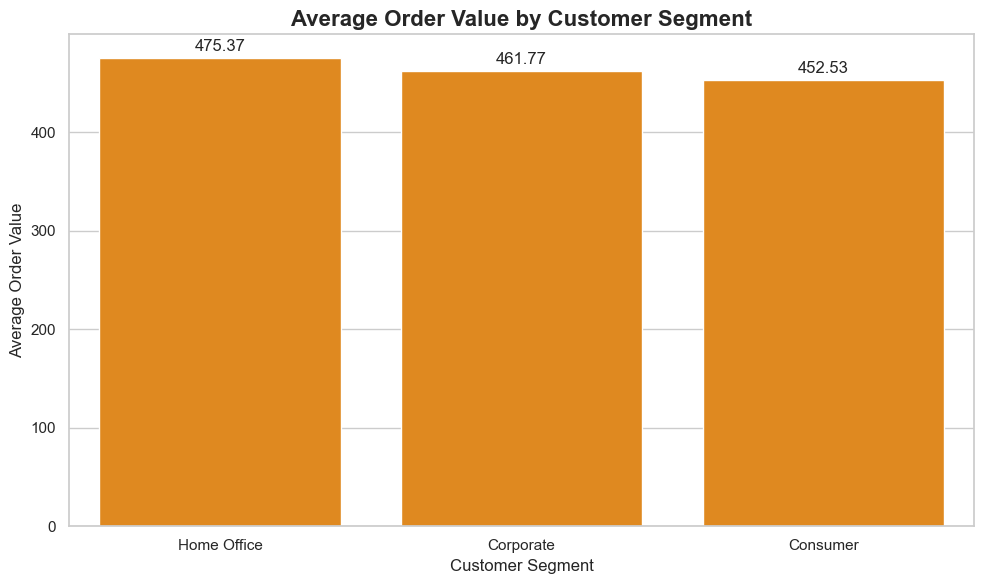

In [14]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=result4,
    x="segment",
    y="average_order_value",
    color="darkorange"
)

ax.set_title(
    "Average Order Value by Customer Segment",
    fontsize=16,
    weight="bold"
)
ax.set_xlabel("Customer Segment")
ax.set_ylabel("Average Order Value")
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()

# Business takeaway:
Average order value helps compare purchasing value across customer segments. The segment with the highest average may respond well to premium product recommendations or complementary product offers.

# Visualization 5: Sales by Product Category

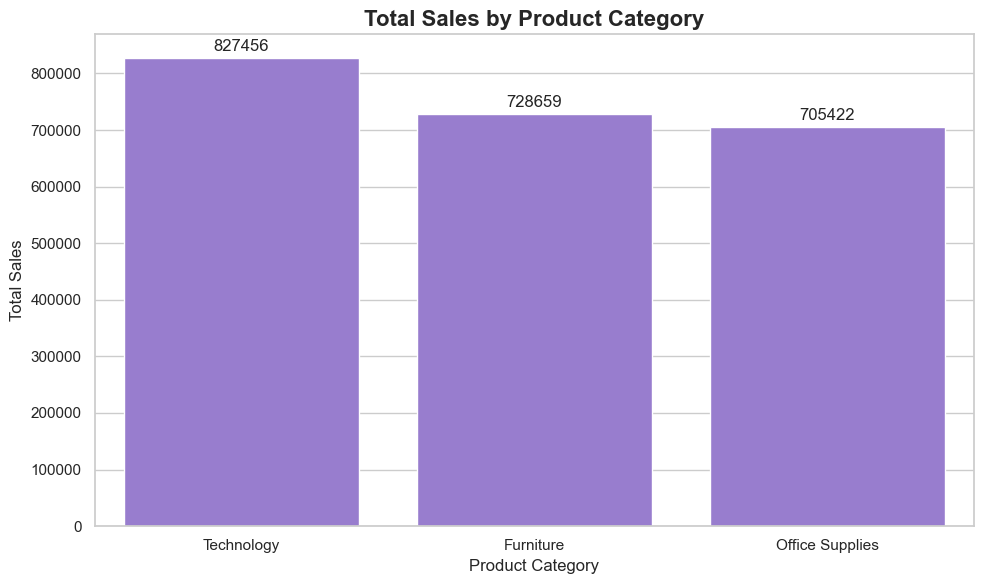

In [15]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=result5,
    x="category",
    y="total_sales",
    color="mediumpurple"
)

ax.set_title("Total Sales by Product Category", fontsize=16, weight="bold")
ax.set_xlabel("Product Category")
ax.set_ylabel("Total Sales")
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

# Business takeaway:
Category-level sales comparisons show which product groups contribute most to revenue. The business can use this information to guide category-level promotions and product assortment decisions.

#  Visualization 6: Distribution of Sales

Business Question: What is the distribution of sales amounts across transactions?

A histogram helps understand how frequently different sales amounts occur.

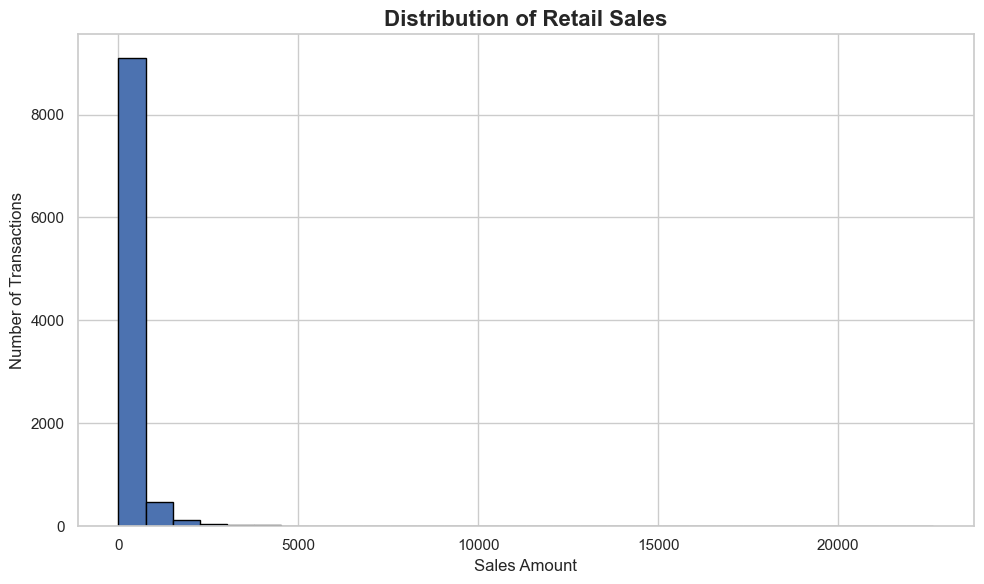

In [20]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

plt.hist(
    df["sales"].dropna(),
    bins=30,
    edgecolor="black"
)

plt.title(
    "Distribution of Retail Sales",
    fontsize=16,
    weight="bold"
)
plt.xlabel("Sales Amount")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

# **Business Takeaway:**

The histogram reveals the most common sales-value ranges and the spread of transaction amounts. A concentration of transactions at lower values with a few high-value transactions may indicate a right-skewed distribution.

# Visualization 7: Sales Across Dataset Records

Business Question: How do individual sales amounts vary across the dataset?

A scatter plot helps identify variation and potentially unusual sales values.

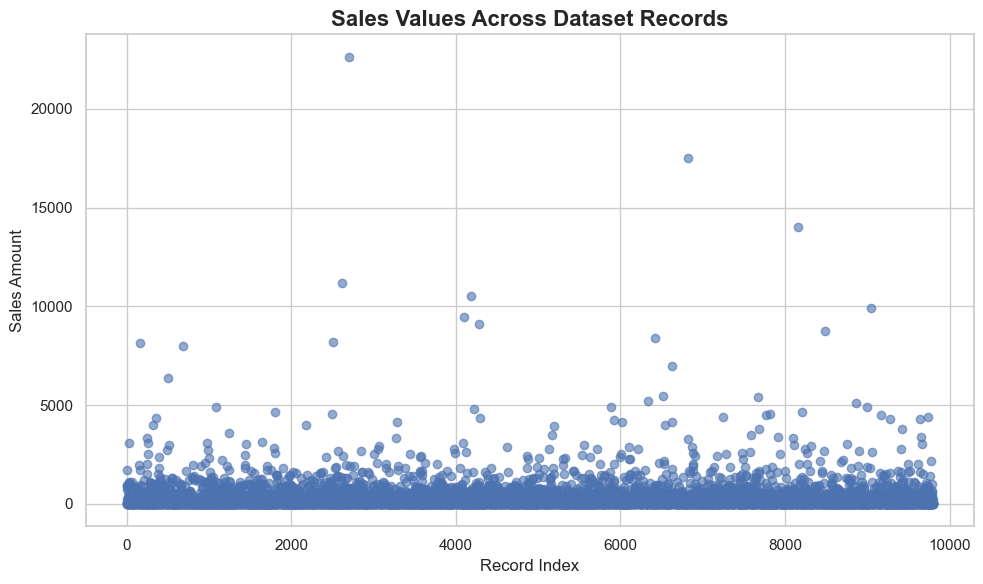

In [21]:
plt.figure(figsize=(10, 6))

plt.scatter(
    range(len(df)),
    df["sales"],
    alpha=0.6
)

plt.title("Sales Values Across Dataset Records", fontsize=16, weight="bold")
plt.xlabel("Record Index")
plt.ylabel("Sales Amount")

plt.tight_layout()
plt.show()

# **Business Takeaway:**

The scatter plot highlights the variation in transaction sales values and makes unusually high values easier to spot for further investigation. The record index is only a plotting position, not a business variable.

# Visualization 8: Sales Contribution by Product Category

Business Question: What percentage of total sales comes from each product category?

A pie chart shows each category's contribution to total sales.

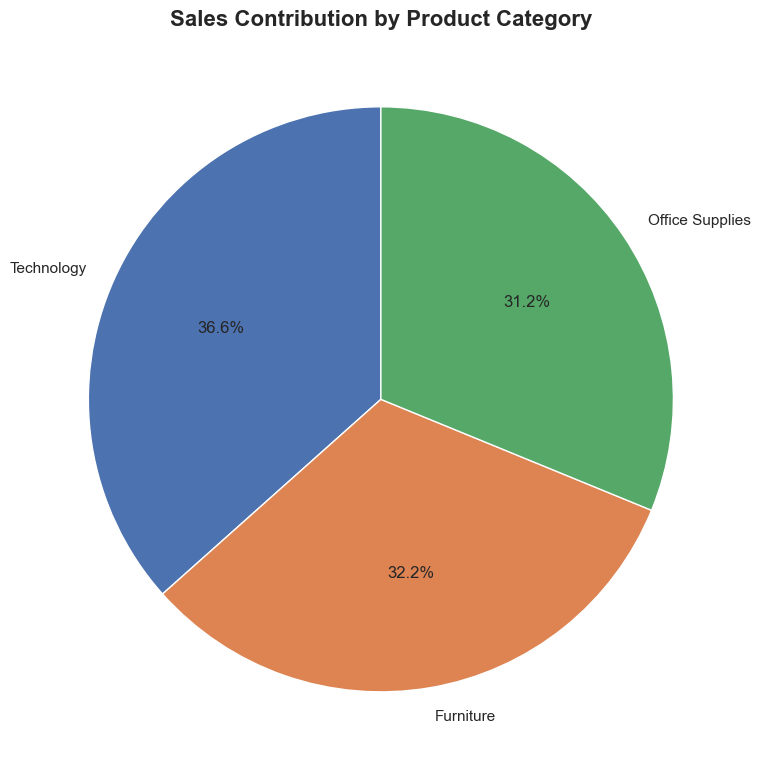

In [22]:
category_sales = (
    df.groupby("category")["sales"]
    .sum()
    .sort_values(ascending=False)
)

if len(category_sales) <= 5:
    plt.figure(figsize=(8, 8))

    plt.pie(
        category_sales,
        labels=category_sales.index,
        autopct="%1.1f%%",
        startangle=90
    )

    plt.title(
        "Sales Contribution by Product Category",
        fontsize=16,
        weight="bold"
    )

    plt.tight_layout()
    plt.show()
else:
    print("More than 5 categories found. A bar chart is more suitable.")

# **Business Takeaway:**

The pie chart shows the percentage contribution of each product category to total sales. This helps identify the categories contributing the largest share of revenue and supports category-level planning.

##  Conclusion

In this milestone, I transformed retail sales data into meaningful visualizations using Python, Matplotlib, and Seaborn.

The project includes eight visualizations:
- Top 10 Products by Sales — Bar Chart
- Monthly Sales Trend — Line Chart
- Sales by Region — Bar Chart
- Average Order Value by Customer Segment — Bar Chart
- Sales by Product Category — Bar Chart
- Distribution of Sales — Histogram
- Sales Across Dataset Records — Scatter Plot
- Sales Contribution by Category — Pie Chart (when suitable)

These visualizations help explore sales patterns, compare business performance across categories and regions, and understand the distribution of transaction values.

This milestone strengthened my skills in data visualization, exploratory data analysis, and communicating business insights through charts.

**Tools Used:** Python, Pandas, Matplotlib, Seaborn, Jupyter Notebook.